# Does RNG change SGM's final accuracy?

Compare **regular SGM (FAQ)** and **GOAT-SGM** on one fixed ER graph pair in each
of three regimes. The main outputs are **three presentation plots**: seed count
on the x-axis, final unseeded accuracy on the y-axis, and the range across RNG
runs shown separately for each seed set.

| Regime | Vertices | Edge probability | Correlation |
|---|---:|---:|---:|
| Sparse ER | 600 | 0.01 | 0.70 |
| Medium sparsity ER | 600 | 16/599 (mean degree 16) | 0.50 |
| Dense ER | 300 | 0.50 | 0.60 |

**Default design:** 10 random seed sets at each of five seed budgets, five RNG
seeds per set, and both solvers on exactly the same sets. This is **1,500 solver
runs**. Expect tens of minutes; results are saved after every run, so an
interrupted collection can resume. Start with `N_SEED_SETS = 2` for a smaller
preview, then increase it to 10: the earlier runs will be reused.

Run the notebook from top to bottom with the project's **ds** kernel. Graph
pairs must be connected and have a discrete color refinement, which certifies
no nontrivial automorphisms. The original sparse pilot pair does not pass these
checks, so this version selects and saves a new structurally valid pair.

These are comparisons between three experimental regimes. Their vertex counts
and correlations also differ, so they do not isolate a causal effect of density.
The dense regime follows the simulation family in the local
[2014 correlated-ER paper](../Literature%20Review/lyzinski14a.pdf).

In [1]:
import csv
import hashlib
import json
import os
import tempfile
import time
import warnings
from dataclasses import replace
from importlib.metadata import version
from pathlib import Path
import sys

os.environ.setdefault('NUMBA_CACHE_DIR', str(Path(tempfile.gettempdir()) / 'sgm_numba_cache'))
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_mpl_cache'))

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / 'experiment_common').is_dir() and (p / 'research_notes').is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from inside the project folder.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from graspologic.match import graph_match
from experiment_common.graphs import generate_graph_pair, preset_config
from experiment_common.graph_checks import check_graph_pair, first_passing_pair
from experiment_common.provenance import collect_environment, thread_limit, write_json

print(f"graspologic {version('graspologic')} | NumPy {np.__version__}")

Matplotlib is building the font cache; this may take a moment.


graspologic 3.4.4 | NumPy 1.26.4


## 1. Choose the sample size and seed budgets

Budgets cover the smaller GOAT transition and the larger FAQ transition. Adjust
them if a curve stays entirely successful or unsuccessful. The graph pair and
existing solver runs remain cached when budgets or sample size are extended.

All three ER regimes start with **GOAT regularizer 100**. This is a specified
comparison, not a claim that 100 is optimal in every regime. If dense GOAT stalls,
its regularizer needs a separate calibration; a flat failure curve is not
evidence of useful seed-quality labels.

In [2]:
N_SEED_SETS = 10
SGM_RNG_SEEDS = [2026, 2027, 2028, 2029, 2030]
SEED_SET_RNG = 20261013
SUCCESS_THRESHOLD = 0.90
MAX_ITER = 100
TOL = 0.01
BLAS_THREADS = 4
TRANSPORT_TOL = 0.05
TRANSPORT_MAX_ITER = 5000
MAX_PAIR_TRIES = 500

REGIMES = [
    dict(id='sparse_er', name='Sparse ER', n=600, p=0.01, rho=0.70,
         first_pair_seed=4192889773, budgets=[5, 8, 16, 26, 36], goat_regularizer=100),
    dict(id='medium_er', name='Medium sparsity ER', n=600, p=16 / 599, rho=0.50,
         first_pair_seed=88424077, budgets=[8, 12, 20, 29, 36], goat_regularizer=100),
    dict(id='dense_er', name='Dense ER', n=300, p=0.50, rho=0.60,
         first_pair_seed=8675309, budgets=[2, 4, 6, 8, 12], goat_regularizer=100),
]

assert N_SEED_SETS >= 1 and len(SGM_RNG_SEEDS) >= 2
assert len(SGM_RNG_SEEDS) == len(set(SGM_RNG_SEEDS))
for regime in REGIMES:
    assert len(regime['budgets']) == len(set(regime['budgets']))
    assert len(regime['budgets']) >= 2
    assert all(0 < k < regime['n'] for k in regime['budgets'])

total_runs = sum(len(r['budgets']) for r in REGIMES) * N_SEED_SETS * len(SGM_RNG_SEEDS) * 2
print(f'{total_runs:,} requested runs: {N_SEED_SETS} sets × {len(SGM_RNG_SEEDS)} RNG seeds × two solvers.')

1,500 requested runs: 10 sets × 5 RNG seeds × two solvers.


## 2. Select and freeze three structurally valid pairs

For each regime, try graph RNG seeds in a fixed order and accept the **first**
pair passing both structural checks. No solver outcomes, edge-retention rates,
or hub sizes are used to accept a pair. A discrete color refinement is a
sufficient certificate of asymmetry; a nondiscrete result is inconclusive and
is rejected here. Selection therefore conditions the sparse family on these
structural requirements.

The seed sets are built from random vertex orderings. Taking the first \(k\)
vertices gives a uniform random \(k\)-subset. Sets are nested across budgets,
and FAQ and GOAT receive identical seed vertices and corresponding seed matches.

In [7]:
# The cache identity excludes sample size and budgets so extensions can reuse runs.
# Changes to graph settings, solver settings, library versions, or thread count
# create a separate experiment directory.
with thread_limit(BLAS_THREADS):
    environment = collect_environment(BLAS_THREADS)
environment['package_versions']['POT'] = version('POT')
source_hashes = {
    name: hashlib.sha256((ROOT / name).read_bytes()).hexdigest()
    for name in ['utils/Graphs.py', 'experiment_common/graphs.py', 'experiment_common/graph_checks.py']
}
protocol = {
    'version': 'faq_goat_rng_curves_v1',
    'regimes': [{k: v for k, v in r.items() if k != 'budgets'} for r in REGIMES],
    'seed_set_rng': SEED_SET_RNG,
    'max_iter': MAX_ITER, 'tol': TOL, 'blas_threads': BLAS_THREADS,
    'transport_tol': TRANSPORT_TOL, 'transport_max_iter': TRANSPORT_MAX_ITER,
    'n_init': 1, 'init_perturbation': 0.0, 'shuffle_input': True,
    'packages': environment['package_versions'],
    'platform': environment['platform'], 'threadpools': environment['threadpools'],
    'source_hashes': source_hashes,
}
fingerprint = hashlib.sha256(json.dumps(protocol, sort_keys=True).encode()).hexdigest()
EXPERIMENT_DIR = ROOT / 'research_notes' / 'data' / 'sgm_rng_variation_diagnostics' / fingerprint[:12]
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)
manifest_path = EXPERIMENT_DIR / 'experiment.json'
if manifest_path.exists():
    assert json.loads(manifest_path.read_text())['fingerprint'] == fingerprint
else:
    write_json(manifest_path, dict(fingerprint=fingerprint, protocol=protocol, environment=environment))
write_json(EXPERIMENT_DIR / 'requested_analysis.json', {
    'n_seed_sets': N_SEED_SETS, 'rng_seeds': SGM_RNG_SEEDS,
    'budgets': {r['id']: r['budgets'] for r in REGIMES},
    'success_threshold': SUCCESS_THRESHOLD,
})

pairs = {}
pair_rows = []
with thread_limit(BLAS_THREADS):
    for regime_index, regime in enumerate(REGIMES):
        pair_path = EXPERIMENT_DIR / f"{regime['id']}_pair.npz"
        info_path = pair_path.with_suffix('.json')
        if pair_path.exists() and info_path.exists():
            info = json.loads(info_path.read_text())
            with np.load(pair_path) as saved:
                A, B, truth = (saved[key] for key in ['A', 'B', 'truth'])
        else:
            config = replace(preset_config('sparse_er'), vertex_count=regime['n'],
                             er_probability=regime['p'], rho=regime['rho'])
            pair_seed, A, B, truth, structure, rejected = first_passing_pair(
                lambda seed: generate_graph_pair(config, seed),
                regime['first_pair_seed'], max_tries=MAX_PAIR_TRIES,
            )
            info = dict(pair_seed=int(pair_seed), rejected_draws=int(rejected), structure=structure)
            np.savez_compressed(pair_path, A=A, B=B, truth=truth)
            write_json(info_path, info)
        structure = check_graph_pair(A, B)
        assert structure['passes'], 'Cached pair no longer passes structural checks.'
        pairs[regime['id']] = dict(A=A, B=B, truth=truth, pair_seed=info['pair_seed'])
        pair_rows.append({
            'Regime': regime['name'], 'n': len(A), 'p': regime['p'], 'rho': regime['rho'],
            'Mean degree A': A.sum(axis=1).mean(), 'Graph-pair seed': info['pair_seed'],
            'Rejected draws': info['rejected_draws'],
            'Both connected': structure['graph1_connected'] and structure['graph2_connected'],
            'Both asymmetric': structure['graph1_n_unresolved'] == structure['graph2_n_unresolved'] == 0,
            'GOAT regularizer': regime['goat_regularizer'],
        })

pair_table = pd.DataFrame(pair_rows).set_index('Regime')
display(pair_table.round(4))
print('Results and figures:', EXPERIMENT_DIR)


def seed_vertices(regime_index, set_id, n, k):
    rng = np.random.default_rng(np.random.SeedSequence([SEED_SET_RNG, regime_index, set_id, 2468]))
    return np.sort(rng.permutation(n)[:k])

,n,p,rho,Mean degree A,Graph-pair seed,Rejected draws,Both connected,Both asymmetric,GOAT regularizer
Regime,,,,,,,,,
Sparse ER,600,0.0100,0.7,6.1367,4192889786,13,True,True,100
Medium sparsity ER,600,0.0267,0.5,15.8800,88424077,0,True,True,100
Dense ER,300,0.5000,0.6,149.3000,8675309,0,True,True,100


Results and figures: /Users/langsong/Desktop/Seeded-Graph-Matching/research_notes/data/sgm_rng_variation_diagnostics/6681f18f968d


## 3. Collect repeated single-run outcomes

Every call uses the public `graspologic.match.graph_match` function with
`n_init=1`. Five explicit calls measure the RNG spread; **no best-of-five
selection** is applied. Accuracy excludes the seeds, which are supplied as
known matches. Cached completed runs are skipped automatically.

In [8]:
RUN_FIELDS = [
    'regime', 'solver', 'k', 'seed_set_id', 'rng_seed', 'graph_pair_seed',
    'seed_vertices', 'accuracy', 'objective', 'n_iter', 'converged',
    'seconds', 'warnings', 'finite_soft_solution', 'soft_distance_from_uniform',
]


def run_key(row):
    return (row['regime'], row['solver'], int(row['k']), int(row['seed_set_id']), int(row['rng_seed']))


def run_once(pair, seeds, solver, rng_seed, regularizer):
    A, B, truth = pair['A'], pair['B'], pair['truth']
    started = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        result = graph_match(
            A, B, partial_match=np.column_stack((seeds, truth[seeds])),
            n_init=1, n_jobs=1, init=None, init_perturbation=0.0,
            shuffle_input=True, max_iter=MAX_ITER, tol=TOL, rng=int(rng_seed),
            transport=solver == 'GOAT', transport_regularizer=regularizer,
            transport_tol=TRANSPORT_TOL, transport_max_iter=TRANSPORT_MAX_ITER,
        )
    prediction = np.empty(len(A), dtype=int)
    prediction[result.indices_A] = result.indices_B
    unseeded = np.setdiff1d(np.arange(len(A)), seeds)
    P = result.misc[0]['convex_solution']
    if not np.isfinite(P).all():
        raise RuntimeError('Nonfinite solver iterate; inspect solver settings before continuing.')
    return dict(
        accuracy=float(np.mean(prediction[unseeded] == truth[unseeded])),
        objective=float(result.score), n_iter=int(result.misc[0]['n_iter']),
        converged=bool(result.misc[0]['converged']), seconds=time.perf_counter() - started,
        warnings=json.dumps([str(w.message) for w in caught]), finite_soft_solution=True,
        soft_distance_from_uniform=float(np.linalg.norm(P - 1 / len(P)) / np.sqrt(len(P))),
    )


RUNS_PATH = EXPERIMENT_DIR / 'runs.csv'
completed = set()
if RUNS_PATH.exists():
    with RUNS_PATH.open(newline='') as f:
        completed = {run_key(row) for row in csv.DictReader(f)}

progress = display('Preparing requested runs...', display_id=True)
processed = new_runs = 0
started = time.perf_counter()
with thread_limit(BLAS_THREADS), RUNS_PATH.open('a', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=RUN_FIELDS)
    if f.tell() == 0:
        writer.writeheader()
    for regime_index, regime in enumerate(REGIMES):
        pair = pairs[regime['id']]
        for k in sorted(regime['budgets']):
            for set_id in range(N_SEED_SETS):
                seeds = seed_vertices(regime_index, set_id, regime['n'], k)
                for solver in ['FAQ', 'GOAT']:
                    for rng_seed in SGM_RNG_SEEDS:
                        row = dict(regime=regime['id'], solver=solver, k=k,
                                   seed_set_id=set_id, rng_seed=rng_seed)
                        if run_key(row) not in completed:
                            outcome = run_once(pair, seeds, solver, rng_seed, regime['goat_regularizer'])
                            writer.writerow({**row, 'graph_pair_seed': pair['pair_seed'],
                                             'seed_vertices': json.dumps(seeds.tolist()), **outcome})
                            f.flush()
                            completed.add(run_key(row))
                            new_runs += 1
                        processed += 1
                progress.update(
                    f"{regime['name']}, k={k}, set {set_id + 1}/{N_SEED_SETS} | "
                    f"{processed:,}/{total_runs:,} requested runs ready | {new_runs:,} newly computed"
                )
progress.update(f'Complete: {total_runs:,} requested runs ready; {new_runs:,} new runs in {(time.perf_counter()-started)/60:.1f} minutes.')

# Keep only the requested sample if the cache also contains an earlier/larger run.
cached = pd.read_csv(RUNS_PATH)
runs = pd.concat([
    cached[(cached.regime == r['id']) & cached.k.isin(r['budgets'])
           & (cached.seed_set_id < N_SEED_SETS) & cached.rng_seed.isin(SGM_RNG_SEEDS)]
    for r in REGIMES
], ignore_index=True)
assert len(runs) == total_runs
assert not runs.duplicated(['regime', 'solver', 'k', 'seed_set_id', 'rng_seed']).any()
assert runs.accuracy.between(0, 1).all()
runs['success'] = runs.accuracy >= SUCCESS_THRESHOLD

'Complete: 1,500 requested runs ready; 0 new runs in 0.0 minutes.'

## 4. Three plots for the meeting

**Thick lines:** average final accuracy across sets and RNG runs.
**Small dots:** a seed set's average across its five RNG runs.
**Thin whiskers:** that same set's minimum and maximum across RNG runs.

Long whiskers mean RNG can change the outcome for a fixed set. Dots at different
heights with short whiskers mean seed selection matters and the solver is
reproducible. These whiskers are observed ranges, **not confidence intervals**.
FAQ dots are shifted slightly left and GOAT dots right for readability; both
were evaluated at exactly the seed counts on the x-axis.

Plots use a common accuracy scale. PNG and PDF versions of each panel, plus a
combined three-panel overview, are saved in the experiment's `figures` folder.

In [9]:
set_stats = (
    runs.groupby(['regime', 'solver', 'k', 'seed_set_id'], sort=False)
    .agg(mean_accuracy=('accuracy', 'mean'), min_accuracy=('accuracy', 'min'),
         max_accuracy=('accuracy', 'max'), rng_sd=('accuracy', lambda x: x.std(ddof=0)),
         successes=('success', 'sum'), rng_runs=('accuracy', 'size'))
    .reset_index()
)
assert set_stats.rng_runs.eq(len(SGM_RNG_SEEDS)).all()
set_stats['rng_range'] = set_stats.max_accuracy - set_stats.min_accuracy
set_stats['mixed_label'] = (set_stats.successes > 0) & (set_stats.successes < set_stats.rng_runs)
set_stats['success_fraction'] = set_stats.successes / set_stats.rng_runs
summary = (
    set_stats.groupby(['regime', 'solver', 'k'], sort=False)
    .agg(mean_accuracy=('mean_accuracy', 'mean'), mean_rng_sd=('rng_sd', 'mean'),
         mean_rng_range=('rng_range', 'mean'), mixed_sets=('mixed_label', 'sum'),
         seed_sets=('seed_set_id', 'size'), success_rate=('success_fraction', 'mean'))
    .reset_index()
)
set_stats.to_csv(EXPERIMENT_DIR / 'seed_set_summary.csv', index=False)
summary.to_csv(EXPERIMENT_DIR / 'summary.csv', index=False)

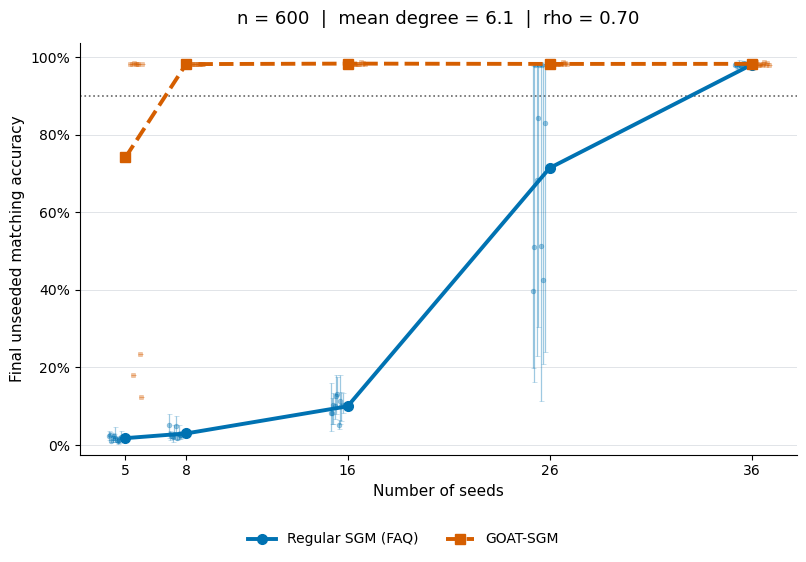

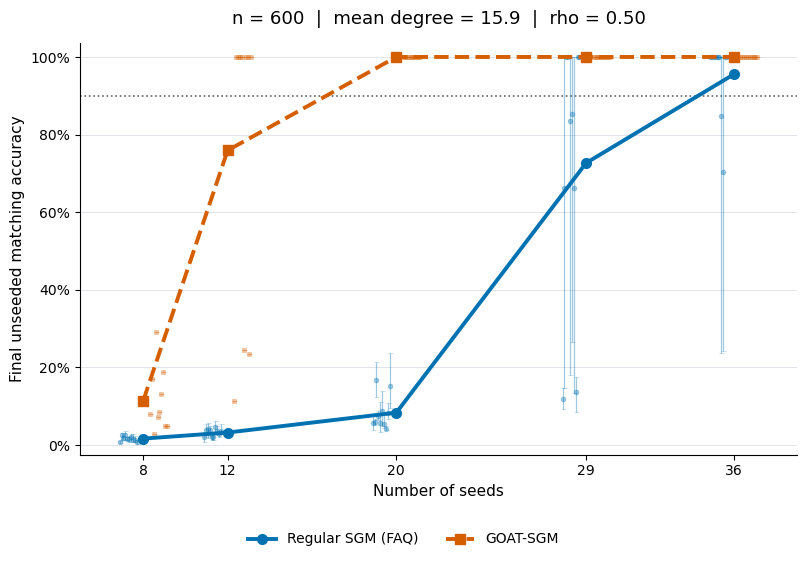

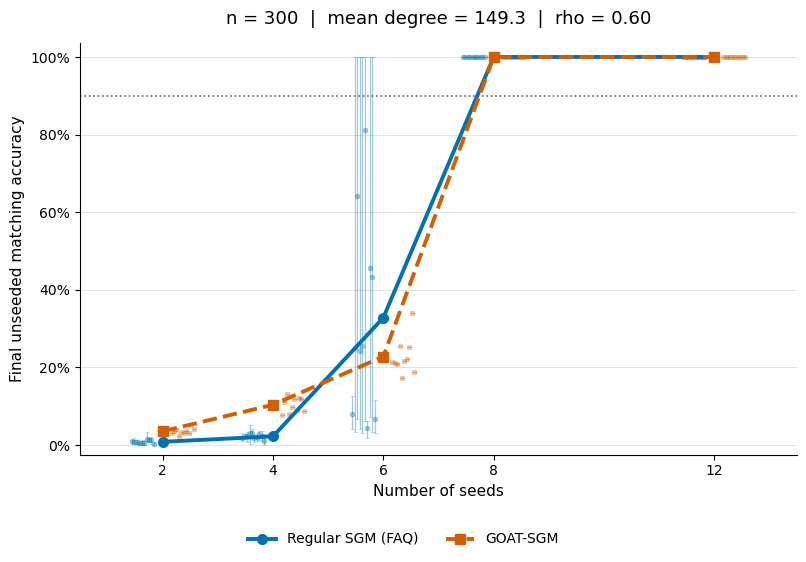

Presentation figures saved to: /Users/langsong/Desktop/Seeded-Graph-Matching/research_notes/data/sgm_rng_variation_diagnostics/6681f18f968d/figures


In [10]:
COLORS = {'FAQ': '#0072B2', 'GOAT': '#D55E00'}
LABELS = {'FAQ': 'Regular SGM (FAQ)', 'GOAT': 'GOAT-SGM'}
MARKERS = {'FAQ': 'o', 'GOAT': 's'}
LINESTYLES = {'FAQ': '-', 'GOAT': '--'}


def plot_regime(ax, regime, set_stats, summary, mean_degree, compact=False):
    budgets = sorted(regime['budgets'])
    spacing = min(np.diff(budgets))
    for solver in ['FAQ', 'GOAT']:
        individual = set_stats[(set_stats.regime == regime['id']) & (set_stats.solver == solver)]
        curve = summary[(summary.regime == regime['id']) & (summary.solver == solver)].sort_values('k')
        for k in budgets:
            group = individual[individual.k == k].sort_values('seed_set_id')
            jitter = np.linspace(-0.10 * spacing, 0.10 * spacing, len(group)) if len(group) > 1 else np.zeros(1)
            offset = (-0.18 if solver == 'FAQ' else 0.18) * spacing
            x = k + offset + jitter
            # Roundoff can make an otherwise zero-width interval slightly negative.
            ax.errorbar(
                x, group.mean_accuracy,
                yerr=np.maximum(0.0, np.vstack((group.mean_accuracy - group.min_accuracy,
                                                 group.max_accuracy - group.mean_accuracy))),
                fmt=MARKERS[solver], markersize=3.5, color=COLORS[solver],
                alpha=0.38, elinewidth=0.9, capsize=1.8, capthick=0.8,
                markeredgewidth=0.4, zorder=2,
            )
        ax.plot(curve.k, curve.mean_accuracy, color=COLORS[solver],
                linestyle=LINESTYLES[solver], marker=MARKERS[solver],
                markersize=7, linewidth=2.8, label=LABELS[solver], zorder=4)
    ax.axhline(SUCCESS_THRESHOLD, color='#666666', linestyle=':', linewidth=1.2, zorder=1)
    ax.set_ylim(-0.025, 1.035)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xticks(budgets)
    ax.set_xlim(budgets[0] - 0.75 * spacing, budgets[-1] + 0.75 * spacing)
    ax.set_xlabel('Number of seeds', fontsize=11)
    ax.set_ylabel('Final unseeded matching accuracy', fontsize=11)
    title = f"n = {regime['n']}  |  mean degree = {mean_degree:.1f}  |  rho = {regime['rho']:.2f}"
    ax.set_title(title, fontsize=12 if compact else 13, pad=14)
    ax.grid(axis='y', color='#D9DDE2', linewidth=0.7, alpha=0.8)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(labelsize=10)


FIGURE_DIR = EXPERIMENT_DIR / 'figures'
FIGURE_DIR.mkdir(exist_ok=True)

with plt.rc_context({'font.family': 'DejaVu Sans', 'font.size': 11, 'figure.facecolor': 'white'}):
    for regime in REGIMES:
        fig, ax = plt.subplots(figsize=(8.2, 5.8))
        degree = pair_table.loc[regime['name'], 'Mean degree A']
        plot_regime(ax, regime, set_stats, summary, degree)
        handles, labels = ax.get_legend_handles_labels()
        fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False,
                   bbox_to_anchor=(0.5, 0.025), fontsize=10)
        fig.tight_layout(rect=(0, 0.10, 1, 1))
        for extension in ['png', 'pdf']:
            fig.savefig(FIGURE_DIR / f"{regime['id']}_faq_vs_goat.{extension}", dpi=250, facecolor='white')
        plt.show()
        plt.close(fig)

    # A slide-sized overview is exported without adding a fourth plot to the notebook.
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.8), sharey=True)
    for ax, regime in zip(axes, REGIMES):
        degree = pair_table.loc[regime['name'], 'Mean degree A']
        plot_regime(ax, regime, set_stats, summary, degree, compact=True)
        if ax is not axes[0]:
            ax.set_ylabel('')
    handles = [Line2D([], [], color=COLORS[s], marker=MARKERS[s], linestyle=LINESTYLES[s],
                      linewidth=2.8, label=LABELS[s]) for s in ['FAQ', 'GOAT']]
    fig.legend(handles=handles, loc='upper center', ncol=2, frameon=False,
               bbox_to_anchor=(0.5, 0.99), fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.91))
    for extension in ['png', 'pdf']:
        fig.savefig(FIGURE_DIR / f'faq_vs_goat_three_regimes.{extension}', dpi=250, facecolor='white')
    plt.close(fig)

print('Presentation figures saved to:', FIGURE_DIR)

## 5. How often does the same seed set switch outcome?

**RNG SD** is the average within-set standard deviation of accuracy, in
percentage points. **Mixed sets** counts sets with at least one success and at
least one failure across the five RNG runs. A stable failure also has zero RNG
variation, so read this table together with the accuracy curves.

In [ ]:
table_rows = []
for regime in REGIMES:
    for k in sorted(regime['budgets']):
        row = {'Regime': regime['name'], 'Seeds': k}
        for solver in ['FAQ', 'GOAT']:
            values = summary[(summary.regime == regime['id']) & (summary.solver == solver) & (summary.k == k)].iloc[0]
            row[f'{solver} RNG SD (pp)'] = round(100 * values.mean_rng_sd, 1)
            row[f'{solver} mixed sets'] = f'{int(values.mixed_sets)}/{int(values.seed_sets)}'
        table_rows.append(row)
meeting_table = pd.DataFrame(table_rows).set_index(['Regime', 'Seeds'])
meeting_table = meeting_table[['FAQ RNG SD (pp)', 'GOAT RNG SD (pp)', 'FAQ mixed sets', 'GOAT mixed sets']]
display(meeting_table)
meeting_table.to_csv(EXPERIMENT_DIR / 'meeting_summary.csv')

# Keep numerical issues visible; no runs are silently excluded from the plots.
quality_table = runs.groupby(['regime', 'solver']).agg(
    runs=('accuracy', 'size'), mean_iterations=('n_iter', 'mean'),
    outer_limit_runs=('converged', lambda x: int((~x).sum())),
    warning_runs=('warnings', lambda x: int(x.ne('[]').sum())),
)
quality_table.to_csv(EXPERIMENT_DIR / 'solver_diagnostics.csv')
if (quality_table[['outer_limit_runs', 'warning_runs']].to_numpy() > 0).any():
    print('Some runs reached the outer iteration limit or emitted warnings. Inspect these before choosing settings:')
    display(quality_table.round(1))
else:
    print('All requested runs met the outer stopping rule without warnings. This does not certify the global optimum.')

## Discussion prompts

- At which seed budgets do FAQ's whiskers become long? Does GOAT remain stable there?
- Can either solver produce both successful and unsuccessful seed sets while each set is reproducible?
- Does GOAT recover the correspondence with fewer seeds, or is a flat curve showing consistent failure?
- Which regime gives a useful range for the next fixed-pair seed-selection experiment?

Interpret each panel as evidence about **one selected graph pair**. Connectivity
and asymmetry remove specific structural ambiguities, but they do not guarantee
that FAQ or GOAT will find the correct matching. The seed sets, RNG seeds, raw
outcomes, settings, and exact graph pairs are saved beside the exported figures.